In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.interpolate import interp1d
import glob
from pathlib import Path

In [2]:
def symmetric_matrix(theta):
    # size of symmetric matrix
    n = int((np.sqrt(1 + 8 * len(theta)) - 1) / 2)
    if len(theta) != n * (n + 1) // 2:
        raise ValueError("Size of theta is invalid for a symmetric matrix")
    # init matrix by generating triangles and then diagonal
    matrix = np.zeros((n, n))
    triu_indices = np.triu_indices(n)
    matrix[triu_indices] = theta
    matrix = matrix + matrix.T - np.diag(np.diag(matrix))
    return np.matrix(matrix)

def extract_theta(symmetric_matrix):
    # extract and flatten to correct shape
    triu_indices = np.triu_indices(symmetric_matrix.shape[0])
    theta = symmetric_matrix[triu_indices]
    return np.array(theta).flatten()

In [3]:
def meta_int(X, t, betat, gamma, mu, Na):
    # solving odes for system
    S = X[:3]
    I = X[3:6]
    Theta = X[6:]
    beta = betat(t)
    Inf = (beta @ I) / Na

    dS = -Inf*S + (Na-S)*mu
    dI = Inf*S - (gamma+mu)*I
   
    # solving Lyapunov equation for covariance
    S = S/Na
    I = I/Na
    J_ss = np.diag([-mu-Inf[0],-mu-Inf[1],-mu-Inf[2]])
    J_si = -beta * S[:, np.newaxis]
    J_is = np.diag([Inf[0],Inf[1],Inf[2]])
    J_ii = -(mu+gamma)*np.eye(3) + beta * S[:, np.newaxis]
    A = np.block([[J_ss,J_si],[J_is,J_ii]])

    B_ss = np.diag([mu*(1-S[0])+S[0]*Inf[0],mu*(1-S[1])+S[1]*Inf[1],mu*(1-S[2])+S[2]*Inf[2]])
    B_si = np.diag([-mu*I[0]-S[0]*Inf[0],-mu*I[1]-S[1]*Inf[1],-mu*S[2]-S[2]*Inf[2]])
    B_ii = np.diag([(gamma+mu)*I[0]+S[0]*Inf[0],(gamma+mu)*I[1]+S[1]*Inf[1],(gamma+mu)*I[2]+S[2]*Inf[2]])
    B = np.block([[B_ss,B_si],[B_si,B_ii]])

    Θ = symmetric_matrix(Theta)
    K = A*Θ+Θ*A.transpose()+B
    return np.concatenate([dS,dI,extract_theta(K)])

$R_0=1/(\gamma+\mu)*\rho(\beta)$

In [4]:
# system parameters
gamma = 0.1
mu = 1/(80*365)
b_w = 0.231
b_b = 0.12
beta_matrix = np.array([[b_w,b_b,0],[b_b,b_w,b_b],[0,b_b,b_w]])
np.max(np.linalg.eigvals(beta_matrix))/(gamma+mu)

4.005684465099393

In [5]:
def analyze_epidemic_data(folder_name, betat, ts, gamma, mu, N_population, Si, Ii, etol):
    # compute theoretical results
    theory = odeint(meta_int, np.append(np.hstack((Si,Ii)), np.zeros(21)), 
                   ts, args=(betat,gamma,mu,N_population))
    cov = [symmetric_matrix(theory[i,6:])[3:,3:] for i in range(len(ts))]
    eigvals = [np.max(np.linalg.eigvalsh(cov[i])) for i in range(len(ts))]
    norm_eigvals = [np.max(np.linalg.eigvalsh(cov[i]))/np.linalg.norm(np.linalg.eigvalsh(cov[i])) 
                   for i in range(len(ts))]
    eigvec = np.array([np.linalg.eigh(cov[i])[1][:,np.argmax(np.linalg.eigh(cov[i])[0])].getA1() 
                      for i in range(len(ts))])
    Reff = [1/(N_population*(gamma+mu))*np.max(np.linalg.eigvals(theory[i,:3]*betat(ts[i]))) 
            for i in range(len(ts))]
    crossings = np.where(np.abs(np.array(Reff) - 1) <= etol)[0]
    if len(crossings) > 1:
        if folder_name == 'newvar':
            crossings = [crossings[2],crossings[-2]]
        else:
            crossings = crossings[0]

    # get simulation results
    file_paths = sorted(glob.glob(f"Old_Cases/Cluster_Results/{folder_name}/C*.npy"))
    data_list = [np.load(fp) for fp in file_paths]
    data = np.stack(data_list, axis=0)[:-1]
    data = data.reshape(-1, 3, 1001)
    data = data[:, :, ::10]
    data = np.floor(data)
    data = np.diff(data)
    mean_per_time = data.mean(axis=0)
    I_lb = np.quantile(data,q=[0.25,0.975],axis=0)
    mean_subtracted = (data - mean_per_time)/np.sqrt(N_population)
    covariances = np.zeros((3, 3, 100))
    for t in range(100):
        snapshot = mean_subtracted[:, :, t]
        covariances[:, :, t] = np.cov(snapshot, rowvar=False)
    sim_eigvals = [np.max(np.linalg.eigvalsh(covariances[:,:,i])) for i in range(100)]
    sim_norm_eigvals = [np.max(np.linalg.eigvalsh(covariances[:,:,i]))/
                       np.linalg.norm(np.linalg.eigvalsh(covariances[:,:,i])) for i in range(100)]
    sim_eigvec = np.array([np.linalg.eigh(covariances[:,:,i])[1][:,np.argmax(np.linalg.eigh(covariances[:,:,i])[0])] 
                          for i in range(100)])
    
    # get simulation Reff
    file_paths = sorted(glob.glob(f"Old_Cases/Cluster_Results/{folder_name}/S*.npy"))
    data_list = [np.load(fp) for fp in file_paths]
    data = np.stack(data_list, axis=0)[:-1]
    data = data.reshape(-1, 3, 1001)
    beta_matrices = np.array([betat(t) for t in ts])
    scaling_factor = 1/(N_population*(gamma+mu))
    eigvals_array = np.zeros((len(data), len(ts)))
    for j in range(len(ts)):
        sim_data = data[:,:,j]
        eigvals_array[:,j] = np.max(np.linalg.eigvals(sim_data[:,:,None] * beta_matrices[j]), axis=1)
    eigvals_array *= scaling_factor
    Reff_sims = np.mean(eigvals_array, axis=0)
    Reff_lb = np.quantile(eigvals_array, q=[0.25,0.975], axis=0)

    return {
        'theory': theory,
        'eigvals': eigvals,
        'norm_eigvals': norm_eigvals,
        'eigvec': eigvec,
        'Reff': Reff,
        'crossings': crossings,
        'mean_per_time': mean_per_time,
        'I_lb': I_lb,
        'sim_eigvals': sim_eigvals,
        'sim_norm_eigvals': sim_norm_eigvals,
        'sim_eigvec': sim_eigvec,
        'Reff_sims': Reff_sims,
        'Reff_lb': Reff_lb
    }

def plot_epidemic_results_single(results, ts, npi_time=None, save_path=None, legend=True, mini_loc = 'center right'):
    fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(10,13), sharex=True)
    
    days = np.arange(100)
    styles = ["solid", "dashed", "dotted"]
    colors = ["#E69F00", "#56B4E9", "#009E73"]
    n = len(days)
    for city in range(3):
        axs[0].plot(days, results["mean_per_time"][city, :n], color=colors[city], alpha=0.7, label=f"Simulation - City {city + 1}", linewidth=1)
        axs[0].fill_between(days, *results["I_lb"][:, city, :n], color=colors[city], alpha=0.15)
        axs[2].plot(days, np.abs(results["sim_eigvec"][:n, city]), color=colors[city], alpha=0.7, linewidth=1)
    ax0 = axs[0].twinx()
    ax1 = axs[1].twinx()
    ax0.plot(ts, results['Reff'][:len(ts)], label=r'$R_t$ - Theory', linewidth=2)
    ax0.plot(ts, results['Reff_sims'][:len(ts)], label=r'$R_t$ - Simulation',linestyle='--')
    ax0.fill_between(ts, results['Reff_lb'][0][:len(ts)], results['Reff_lb'][1][:len(ts)], alpha=0.2)
    axs[1].plot(days, results["sim_eigvals"][:n], label=r"$\lambda_1$")
    ax1.plot(days, results["sim_norm_eigvals"][:n], color='k', label=r"$\lambda_1/\|\lambda\|_2$")
    roots = ts[results["crossings"]]
    for ax in axs:
        for root in roots[(roots >= ts[0]) & (roots <= ts[-1])]:
            ax.axvline(root, color="k", linestyle="--", alpha=0.6)
        if npi_time is not None and ts[0] <= npi_time <= ts[-1]:
            ax.axvline(npi_time, color="k", alpha=0.6)
        ax.grid(alpha=0.2)
        ax.tick_params(labelsize=12)
    labels = ["Number of cases", r"$R_t$", r"$\lambda_1$",
              r"$\lambda_1/\|\lambda\|_2$", "Absolute dominant eigenvector"]
    axs_label = [axs[0], ax0, axs[1], ax1, axs[2]]
    for ax, label in zip(axs_label, labels):
        ax.set_ylabel(label, fontsize=13)
    axs[0].set_ylim(bottom=0)
    axs[1].set_ylim(bottom=0)
    axs[2].set_ylim(bottom=0)
    ax1.set_ylim(0, 1.05)
    axs[2].set_ylim(0, 1.05)
    axs[-1].set_xlabel("Time (days)", fontsize=13)
    if legend:
        twin_pairs = [(axs[0], ax0), (axs[1], ax1)]
        for primary_ax, secondary_ax in twin_pairs:
            handles, labels_text = primary_ax.get_legend_handles_labels()
            if secondary_ax is not None:
                h2, l2 = secondary_ax.get_legend_handles_labels()
                handles += h2
                labels_text += l2
            if primary_ax == axs[1]:
                primary_ax.legend(handles, labels_text, fontsize=10, loc="center right")
            else:
                primary_ax.legend(handles, labels_text, fontsize=10, loc="upper right")
    if save_path:
        path = Path(save_path)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [6]:
def analyze_epidemic_data_cumulative(folder_name, betat, ts, gamma, mu, N_population, Si, Ii, etol):
    # compute theoretical results
    theory = odeint(meta_int, np.append(np.hstack((Si,Ii)), np.zeros(21)), 
                   ts, args=(betat,gamma,mu,N_population))
    cov = [symmetric_matrix(theory[i,6:])[3:,3:] for i in range(len(ts))]
    eigvals = [np.max(np.linalg.eigvalsh(cov[i])) for i in range(len(ts))]
    norm_eigvals = [np.max(np.linalg.eigvalsh(cov[i]))/np.linalg.norm(np.linalg.eigvalsh(cov[i])) 
                   for i in range(len(ts))]
    eigvec = np.array([np.linalg.eigh(cov[i])[1][:,np.argmax(np.linalg.eigh(cov[i])[0])].getA1() 
                      for i in range(len(ts))])
    Reff = [1/(N_population*(gamma+mu))*np.max(np.linalg.eigvals(theory[i,:3]*betat(ts[i]))) 
            for i in range(len(ts))]
    crossings = np.where(np.abs(np.array(Reff) - 1) <= etol)[0]
    if len(crossings) > 1:
        if folder_name == 'newvar':
            crossings = [crossings[2],crossings[-2]]
        else:
            crossings = crossings[0]

    # get simulation results
    file_paths = sorted(glob.glob(f"Old_Cases/Cluster_Results/{folder_name}/C*.npy"))
    data_list = [np.load(fp) for fp in file_paths]
    data = np.stack(data_list, axis=0)[:-1]
    data = data.reshape(-1, 3, 1001)
    data = data[:, :, ::10]
    mean_per_time = data.mean(axis=0)
    I_lb = np.quantile(data,q=[0.25,0.975],axis=0)
    mean_subtracted = (data - mean_per_time)/np.sqrt(N_population)
    covariances = np.zeros((3, 3, 101))
    for t in range(101):
        snapshot = mean_subtracted[:, :, t]
        covariances[:, :, t] = np.cov(snapshot, rowvar=False)
    sim_eigvals = [np.max(np.linalg.eigvalsh(covariances[:,:,i])) for i in range(101)]
    sim_norm_eigvals = [np.max(np.linalg.eigvalsh(covariances[:,:,i]))/
                       np.linalg.norm(np.linalg.eigvalsh(covariances[:,:,i])) for i in range(101)]
    sim_eigvec = np.array([np.linalg.eigh(covariances[:,:,i])[1][:,np.argmax(np.linalg.eigh(covariances[:,:,i])[0])] 
                          for i in range(101)])
    # get simulation Reff
    file_paths = sorted(glob.glob(f"Old_Cases/Cluster_Results/{folder_name}/S*.npy"))
    data_list = [np.load(fp) for fp in file_paths]
    data = np.stack(data_list, axis=0)[:-1]
    data = data.reshape(-1, 3, 1001)
    beta_matrices = np.array([betat(t) for t in ts])
    scaling_factor = 1/(N_population*(gamma+mu))
    eigvals_array = np.zeros((len(data), len(ts)))
    for j in range(len(ts)):
        sim_data = data[:,:,j]
        eigvals_array[:,j] = np.max(np.linalg.eigvals(sim_data[:,:,None] * beta_matrices[j]), axis=1)
    eigvals_array *= scaling_factor
    Reff_sims = np.mean(eigvals_array, axis=0)
    Reff_lb = np.quantile(eigvals_array, q=[0.25,0.975], axis=0)

    return {
        'theory': theory,
        'eigvals': eigvals,
        'norm_eigvals': norm_eigvals,
        'eigvec': eigvec,
        'Reff': Reff,
        'crossings': crossings,
        'mean_per_time': mean_per_time,
        'I_lb': I_lb,
        'sim_eigvals': sim_eigvals,
        'sim_norm_eigvals': sim_norm_eigvals,
        'sim_eigvec': sim_eigvec,
        'Reff_sims': Reff_sims,
        'Reff_lb': Reff_lb
    }
def plot_epidemic_results_single_cumulative(results, ts, npi_time=None, save_path=None, legend=True, mini_loc = 'center right'):
    fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(10,13), sharex=True)
    
    days = np.arange(100)
    styles = ["solid", "dashed", "dotted"]
    colors = ["#E69F00", "#56B4E9", "#009E73"]
    n = len(days)
    for city in range(3):
        axs[0].plot(days, results["mean_per_time"][city, :n], color=colors[city], alpha=0.7, label=f"Simulation - City {city + 1}", linewidth=1)
        axs[0].fill_between(days, *results["I_lb"][:, city, :n], color=colors[city], alpha=0.15)
        axs[2].plot(days, np.abs(results["sim_eigvec"][:n, city]), color=colors[city], alpha=0.7, linewidth=1)
    ax0 = axs[0].twinx()
    ax1 = axs[1].twinx()
    ax0.plot(ts, results['Reff'][:len(ts)], label=r'$R_t$ - Theory', linewidth=2)
    ax0.plot(ts, results['Reff_sims'][:len(ts)], label=r'$R_t$ - Simulation',linestyle='--')
    ax0.fill_between(ts, results['Reff_lb'][0][:len(ts)], results['Reff_lb'][1][:len(ts)], alpha=0.2)
    axs[1].plot(days, results["sim_eigvals"][:n], label=r"$\lambda_1$")
    ax1.plot(days, results["sim_norm_eigvals"][:n], color='k', label=r"$\lambda_1/\|\lambda\|_2$")
    roots = ts[results["crossings"]]
    for ax in axs:
        for root in roots[(roots >= ts[0]) & (roots <= ts[-1])]:
            ax.axvline(root, color="k", linestyle="--", alpha=0.6)
        if npi_time is not None and ts[0] <= npi_time <= ts[-1]:
            ax.axvline(npi_time, color="k", alpha=0.6)
        ax.grid(alpha=0.2)
        ax.tick_params(labelsize=12)
    labels = ["Number of cumulative cases", r"$R_t$", r"$\lambda_1$",
              r"$\lambda_1/\|\lambda\|_2$", "Absolute dominant eigenvector"]
    axs_label = [axs[0], ax0, axs[1], ax1, axs[2]]
    for ax, label in zip(axs_label, labels):
        ax.set_ylabel(label, fontsize=13)
    axs[0].set_ylim(bottom=0)
    axs[1].set_ylim(bottom=0)
    axs[2].set_ylim(bottom=0)
    ax1.set_ylim(0, 1.05)
    axs[2].set_ylim(0, 1.05)
    axs[-1].set_xlabel("Time (days)", fontsize=13)
    if legend:
        twin_pairs = [(axs[0], ax0), (axs[1], ax1)]
        for primary_ax, secondary_ax in twin_pairs:
            handles, labels_text = primary_ax.get_legend_handles_labels()
            if secondary_ax is not None:
                h2, l2 = secondary_ax.get_legend_handles_labels()
                handles += h2
                labels_text += l2
            if primary_ax == axs[1]:
                primary_ax.legend(handles, labels_text, fontsize=10, loc="center right")
            else:
                primary_ax.legend(handles, labels_text, fontsize=10, loc="upper right")
    if save_path:
        path = Path(save_path)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## Constant $\beta$

In [7]:
# parameters
N_cities = 3
T_max = 100
b_w = 0.231
b_b = 0.12
beta_matrix = np.array([[b_w,b_b,0],[b_b,b_w,b_b],[0,b_b,b_w]])
gamma = 0.1
mu = 1/(80*365)
N_population = 100000

Ii = np.array([100,100,100])
Si = N_population - Ii

betat = lambda t: beta_matrix
days = np.arange(0,101,1)
ts = np.arange(0,100.1,0.1)
results_constant = analyze_epidemic_data('constant', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)

/tmp/ipykernel_6870/3757715960.py:7: RuntimeWarning: invalid value encountered in scalar divide
  norm_eigvals = [np.max(np.linalg.eigvalsh(cov[i]))/np.linalg.norm(np.linalg.eigvalsh(cov[i]))


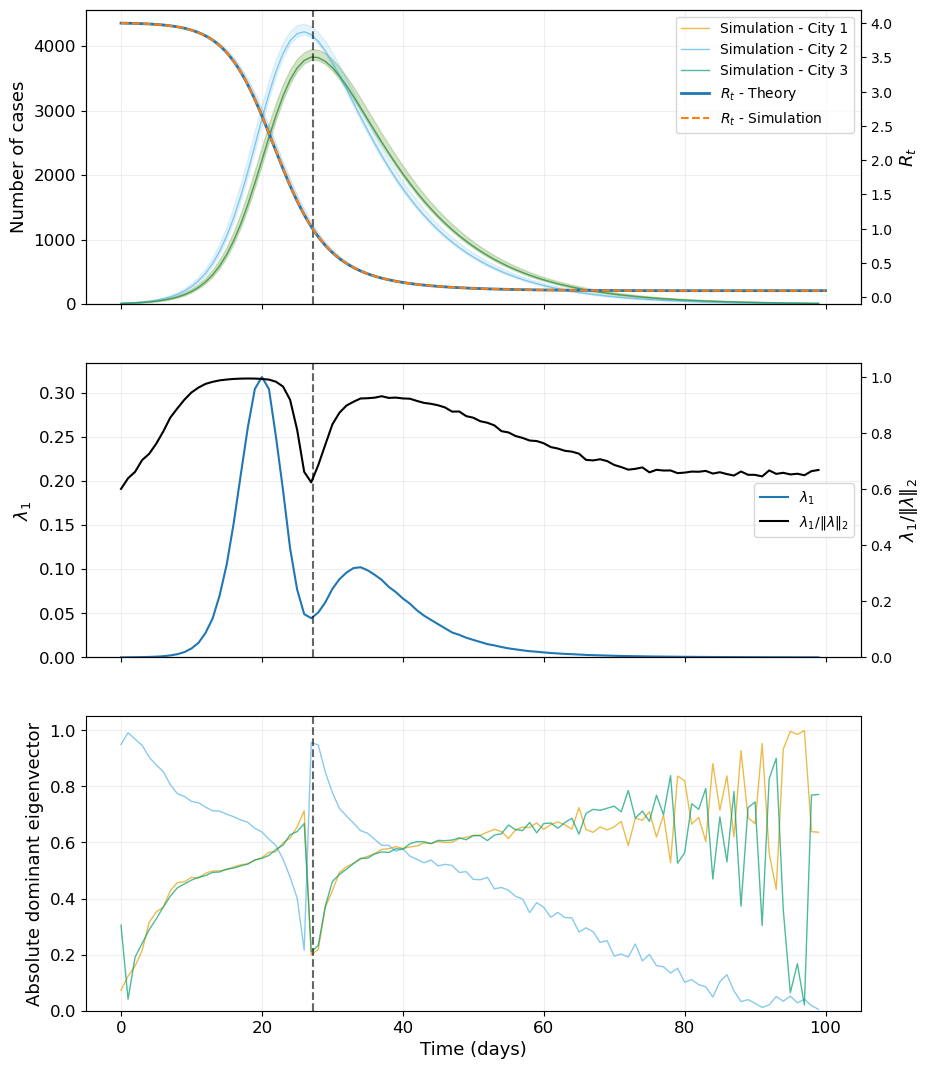

In [9]:
plot_epidemic_results_single(results_constant, ts, save_path='Rev_Figures/cst_cases.pdf')

/tmp/ipykernel_6870/1529226588.py:7: RuntimeWarning: invalid value encountered in scalar divide
  norm_eigvals = [np.max(np.linalg.eigvalsh(cov[i]))/np.linalg.norm(np.linalg.eigvalsh(cov[i]))
/tmp/ipykernel_6870/1529226588.py:34: RuntimeWarning: invalid value encountered in scalar divide
  sim_norm_eigvals = [np.max(np.linalg.eigvalsh(covariances[:,:,i]))/


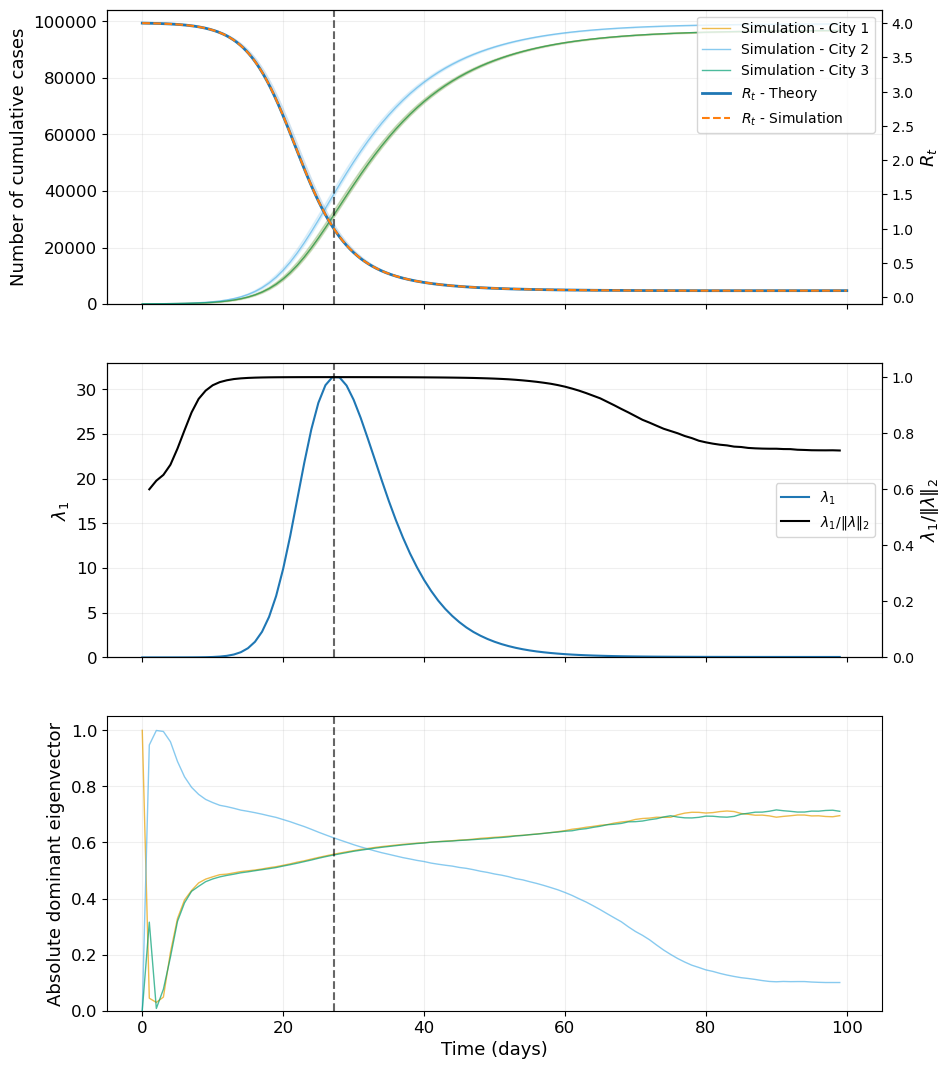

In [10]:
results_constant = analyze_epidemic_data_cumulative('constant', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single_cumulative(results_constant, ts, save_path='Rev_Figures/cst_cases_cumulative.pdf')

/tmp/ipykernel_6870/1529226588.py:7: RuntimeWarning: invalid value encountered in scalar divide
  norm_eigvals = [np.max(np.linalg.eigvalsh(cov[i]))/np.linalg.norm(np.linalg.eigvalsh(cov[i]))
/tmp/ipykernel_6870/1529226588.py:34: RuntimeWarning: invalid value encountered in scalar divide
  sim_norm_eigvals = [np.max(np.linalg.eigvalsh(covariances[:,:,i]))/


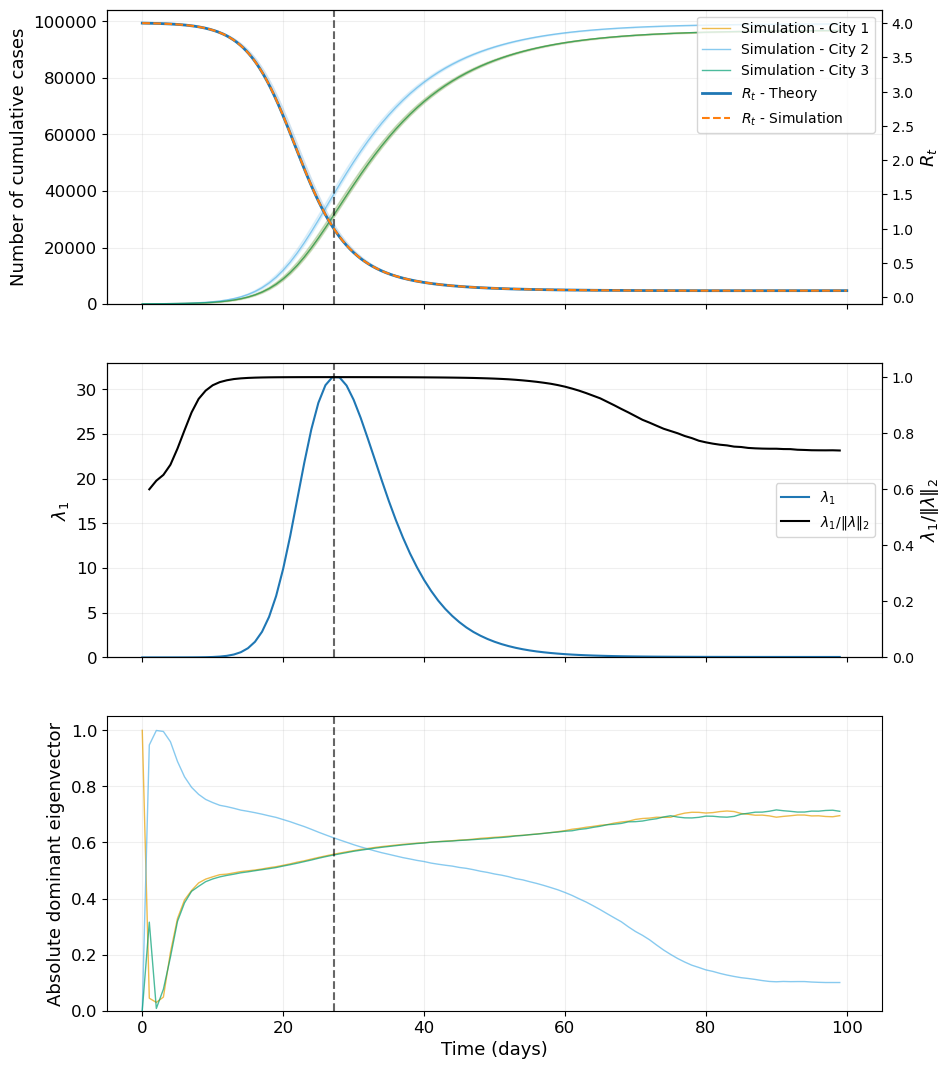

In [11]:
results_constant = analyze_epidemic_data_cumulative('constant', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single_cumulative(results_constant, ts, save_path='Rev_Figures/cst_cases_cumulative.pdf')

## Just b[1,1], full epidemic

/tmp/ipykernel_6870/3757715960.py:7: RuntimeWarning: invalid value encountered in scalar divide
  norm_eigvals = [np.max(np.linalg.eigvalsh(cov[i]))/np.linalg.norm(np.linalg.eigvalsh(cov[i]))


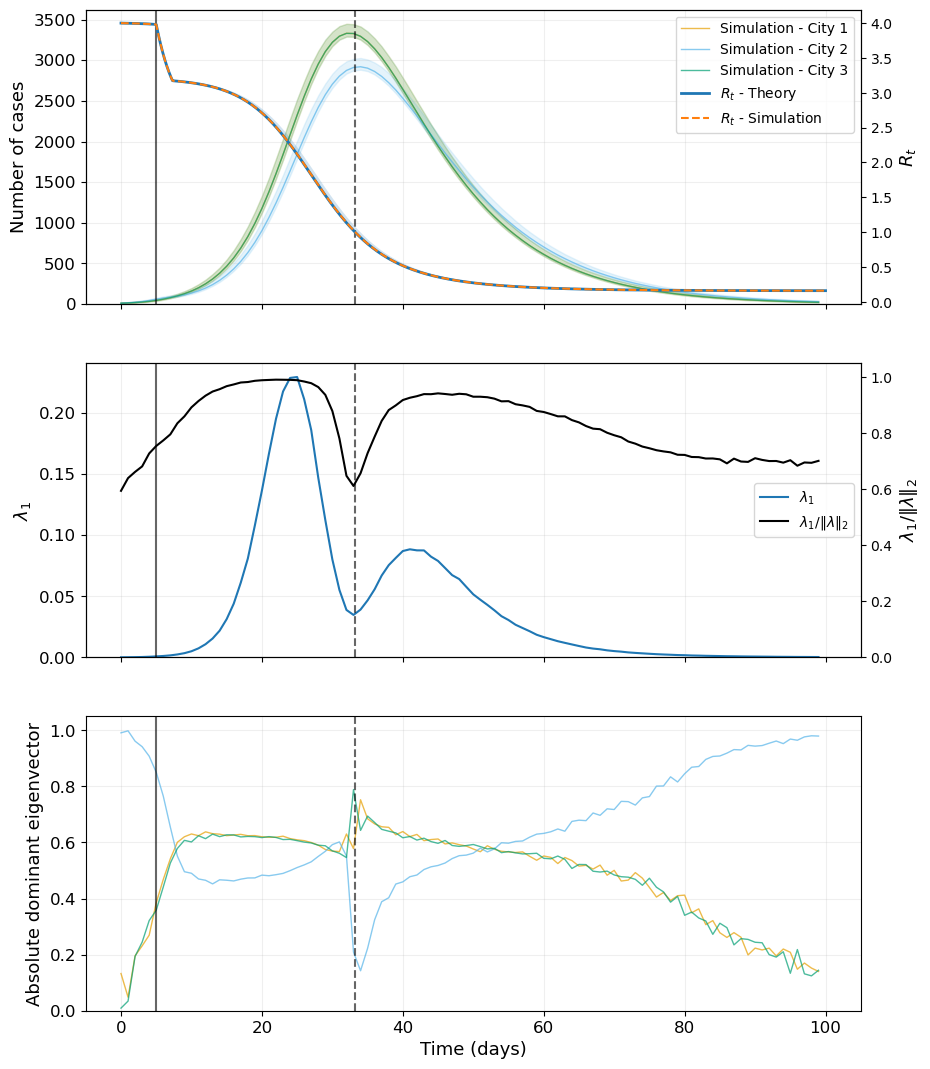

In [12]:
def betat(t):
    if t < 5:
        return beta_matrix
    else:
        temp = np.diag([0,1,0])
        return beta_matrix - 0.1*(t-5)*temp if (beta_matrix - 0.1*(t-5)*temp >= 0).all() else beta_matrix - np.diag([0,beta_matrix[1,1],0])
results_incity = analyze_epidemic_data('indec', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single(results_incity, ts, npi_time=5, save_path='Rev_Figures/in_city_cases.pdf')

/tmp/ipykernel_6870/1529226588.py:7: RuntimeWarning: invalid value encountered in scalar divide
  norm_eigvals = [np.max(np.linalg.eigvalsh(cov[i]))/np.linalg.norm(np.linalg.eigvalsh(cov[i]))
/tmp/ipykernel_6870/1529226588.py:34: RuntimeWarning: invalid value encountered in scalar divide
  sim_norm_eigvals = [np.max(np.linalg.eigvalsh(covariances[:,:,i]))/


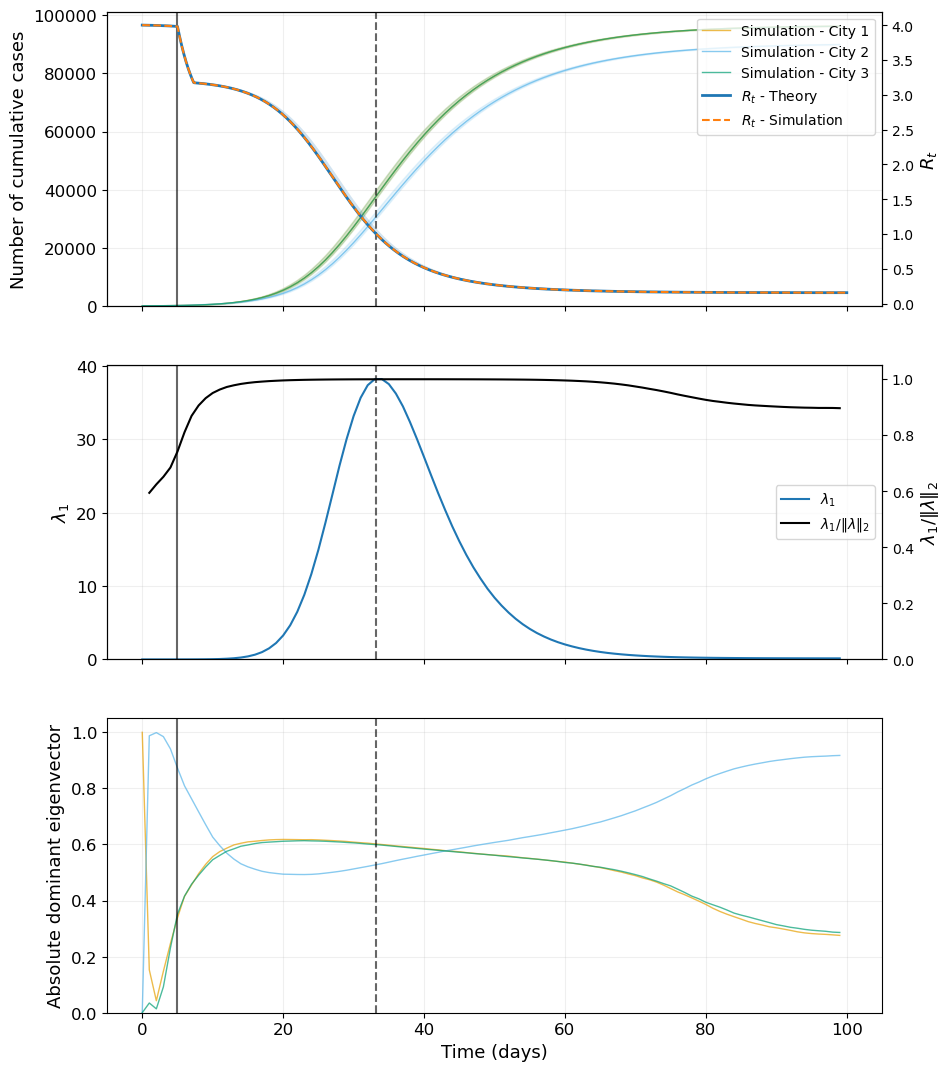

In [13]:
results_incity = analyze_epidemic_data_cumulative('indec', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single_cumulative(results_incity, ts, npi_time=5, save_path='Rev_Figures/in_city_cases_cumulative.pdf')

## Between cities

/tmp/ipykernel_6870/3757715960.py:7: RuntimeWarning: invalid value encountered in scalar divide
  norm_eigvals = [np.max(np.linalg.eigvalsh(cov[i]))/np.linalg.norm(np.linalg.eigvalsh(cov[i]))


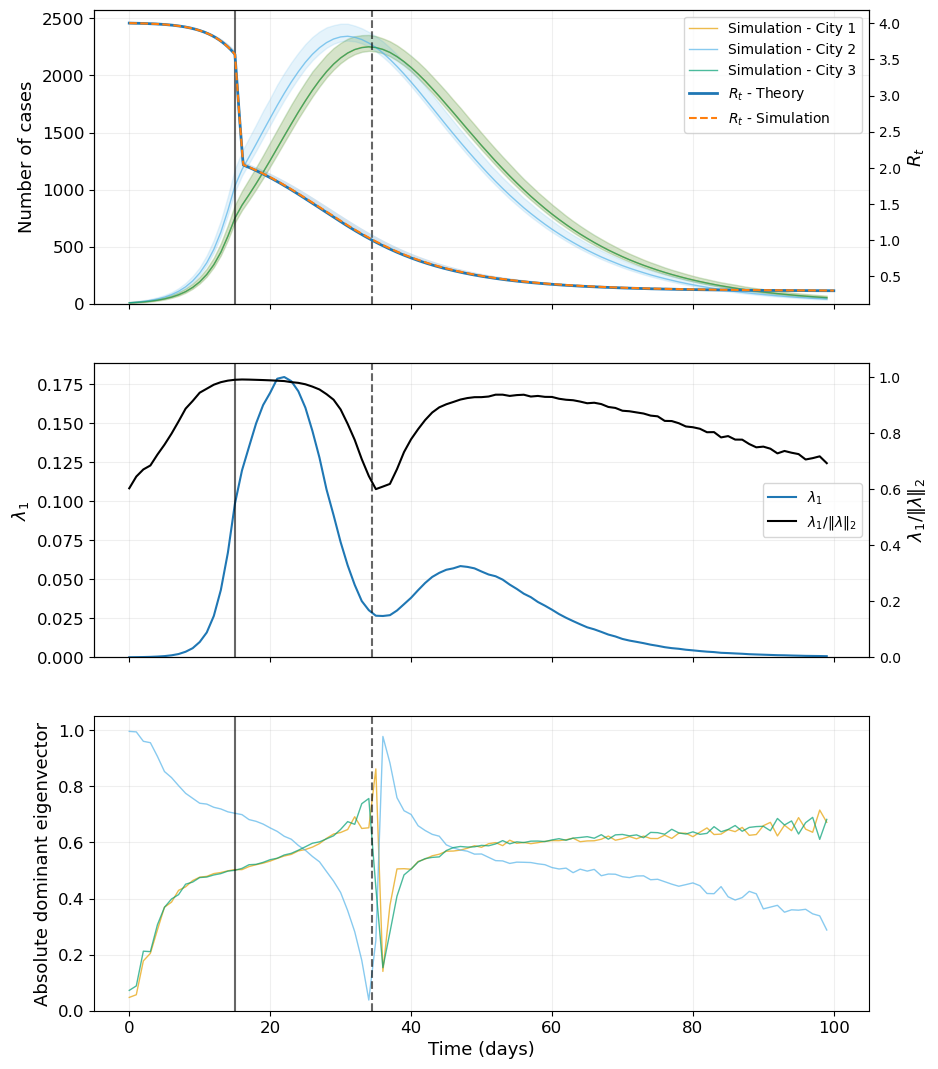

In [14]:
def betat(t):
    if t < 15:
        return beta_matrix
    else:
        temp = np.array([[0,1,0],[1,0,1],[0,1,0]])
        return beta_matrix - 0.1*(t-15)*temp if (beta_matrix - 0.1*(t-15)*temp >= 0).all() else beta_matrix - np.array([[0,b_b,0],[b_b,0,b_b],[0,b_b,0]])

results_between = analyze_epidemic_data('betdec', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single(results_between, ts, npi_time=15, save_path='Rev_Figures/bet_city_cases.pdf')

/tmp/ipykernel_6870/1529226588.py:7: RuntimeWarning: invalid value encountered in scalar divide
  norm_eigvals = [np.max(np.linalg.eigvalsh(cov[i]))/np.linalg.norm(np.linalg.eigvalsh(cov[i]))
/tmp/ipykernel_6870/1529226588.py:34: RuntimeWarning: invalid value encountered in scalar divide
  sim_norm_eigvals = [np.max(np.linalg.eigvalsh(covariances[:,:,i]))/


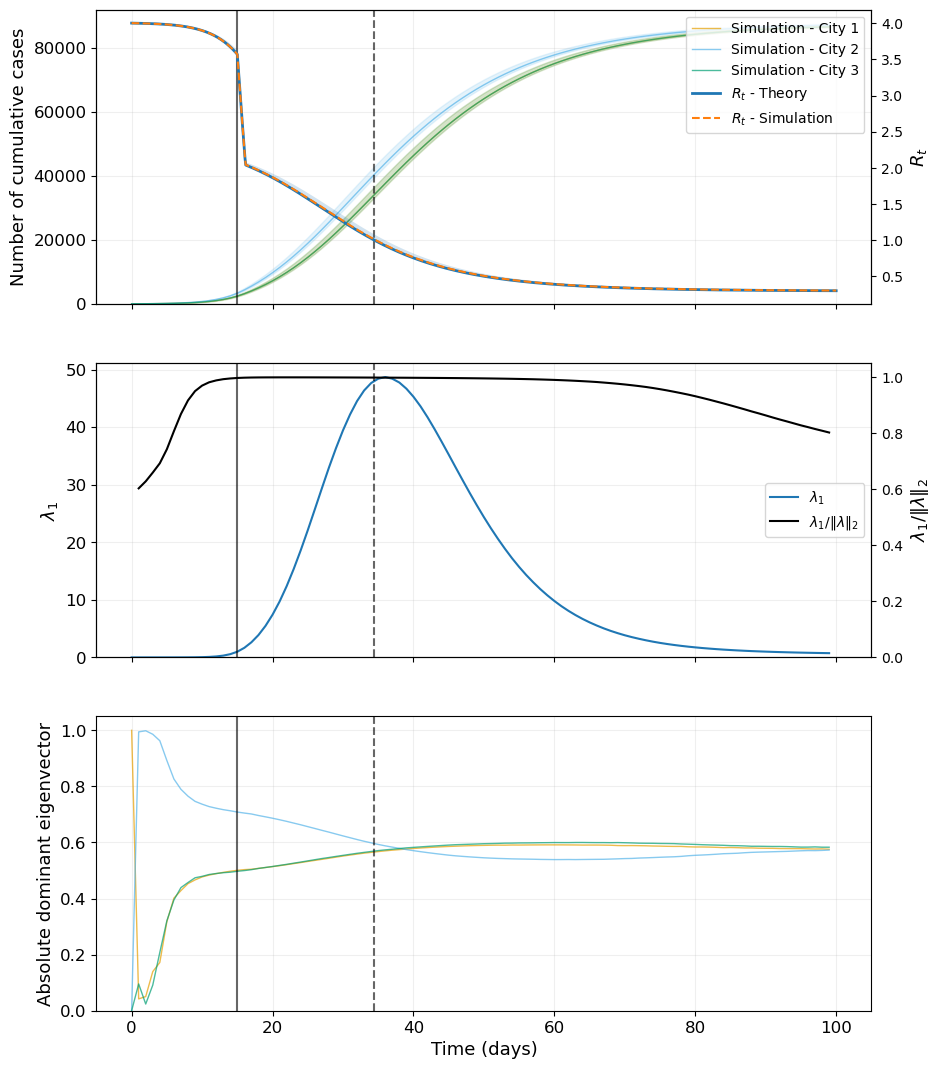

In [15]:
results_between = analyze_epidemic_data_cumulative('betdec', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single_cumulative(results_between, ts, npi_time=15, save_path='Rev_Figures/bet_city_cases_cumulative.pdf')

## New variant

0.8532611778611298
1.3303954541400647


/tmp/ipykernel_6870/3757715960.py:7: RuntimeWarning: invalid value encountered in scalar divide
  norm_eigvals = [np.max(np.linalg.eigvalsh(cov[i]))/np.linalg.norm(np.linalg.eigvalsh(cov[i]))


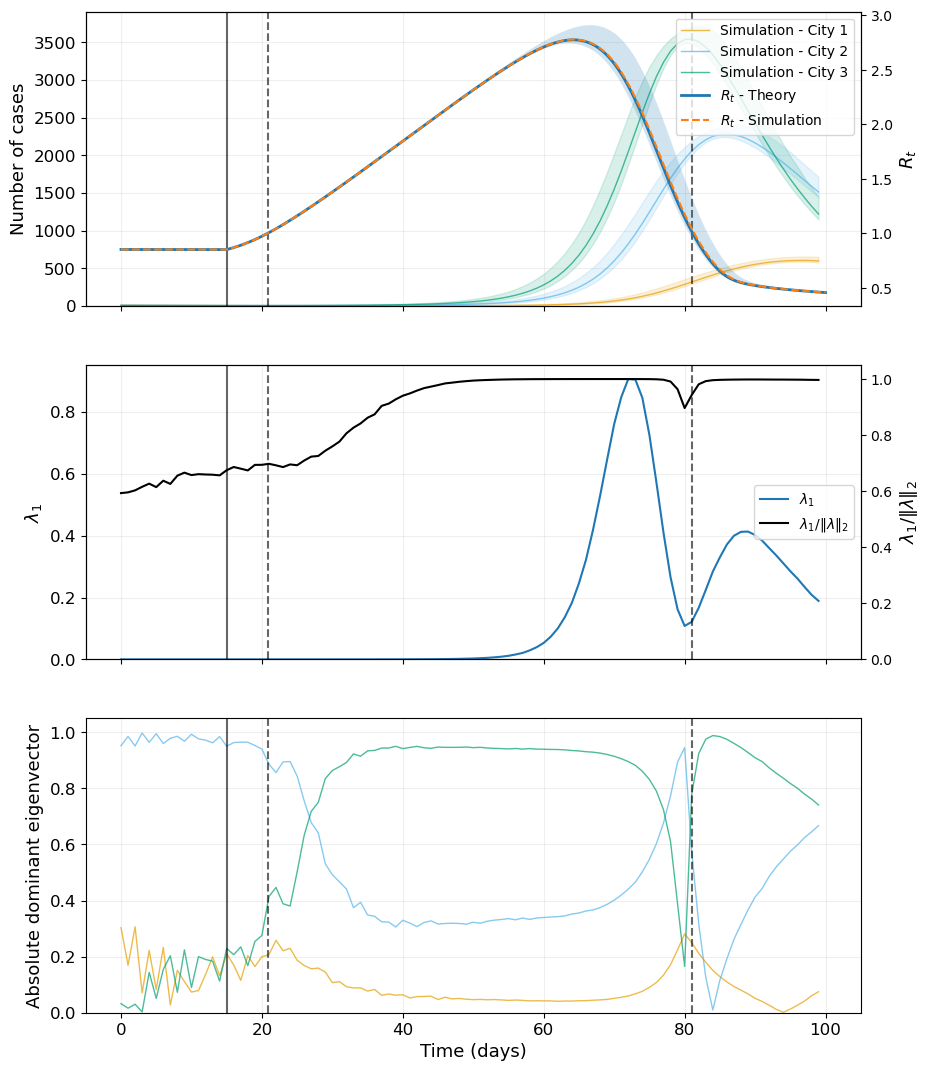

In [16]:
N_cities = 3
T_max = 100
N_population = 100000

Ii = np.array([100,100,100])
Si = N_population - Ii

def betat(t):
    b_w_l = 0.05
    b_b_l = 0.025
    beta_matrix_low = np.array([[b_w_l, b_b_l, 0],
                                [b_b_l, b_w_l, b_b_l],
                                [0,     b_b_l, b_w_l]])
    if t < 15:
        return beta_matrix_low
    else:
        temp = np.array([[0,0,0],
                         [0,0,0.25],
                         [0,0,1]])
        return beta_matrix_low + 0.005*(t-15)*temp

gamma = 0.1
mu = 1/(80*365)
b_w_l = 0.05
b_b_l = 0.025
beta_matrix_low = np.array([[b_w_l,b_b_l,0],[b_b_l,b_w_l,b_b_l],[0,b_b_l,b_w_l]])
print(np.max(np.linalg.eigvals(beta_matrix_low))/(gamma+mu))
beta_matrix_var = np.array([[b_w_l,b_b_l,0],[b_b_l,b_w_l,0.1],[0,b_b_l,0.1]])
print(np.max(np.linalg.eigvals(beta_matrix_var))/(gamma+mu))

results_nv = analyze_epidemic_data('newvar', betat, ts, gamma, mu, N_population, Si, Ii, 0.008)
plot_epidemic_results_single(results_nv, ts, npi_time=15, save_path='Rev_Figures/new_var_cases.pdf')

/tmp/ipykernel_6870/1529226588.py:7: RuntimeWarning: invalid value encountered in scalar divide
  norm_eigvals = [np.max(np.linalg.eigvalsh(cov[i]))/np.linalg.norm(np.linalg.eigvalsh(cov[i]))
/tmp/ipykernel_6870/1529226588.py:34: RuntimeWarning: invalid value encountered in scalar divide
  sim_norm_eigvals = [np.max(np.linalg.eigvalsh(covariances[:,:,i]))/


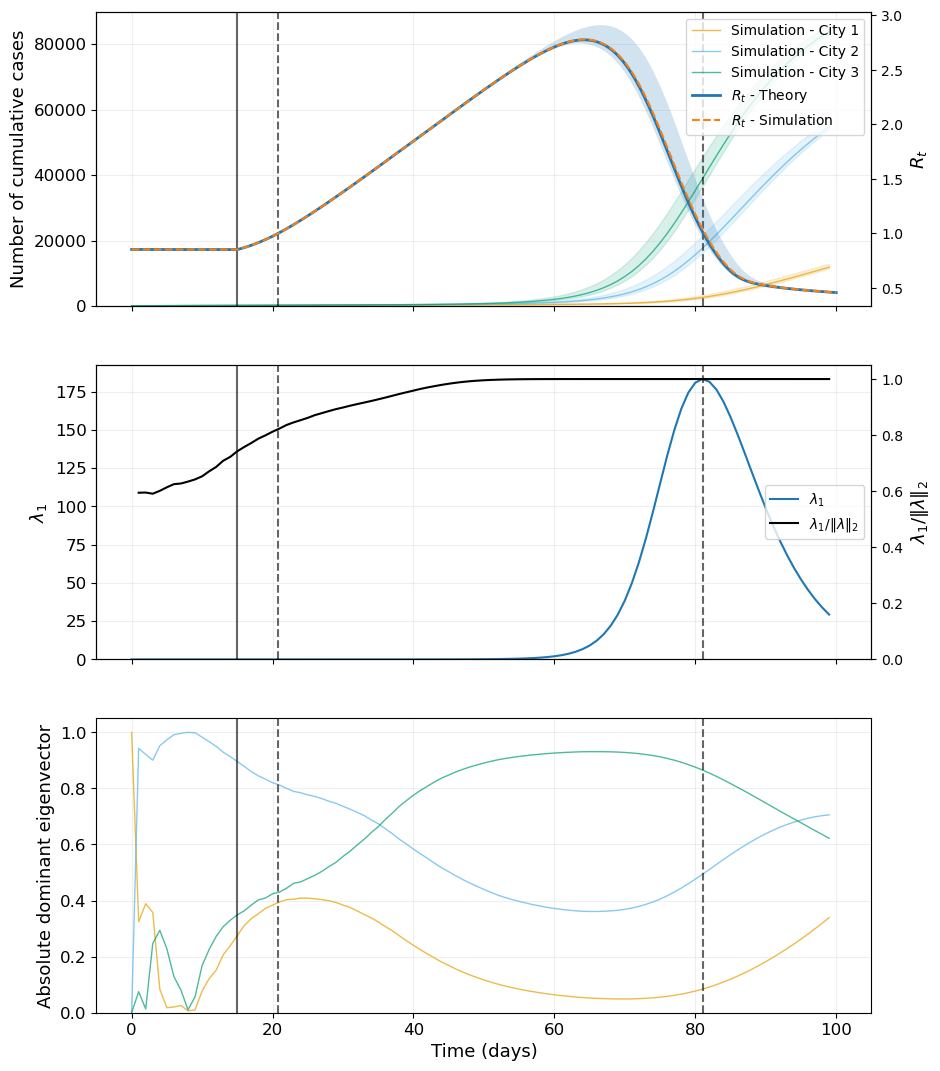

In [17]:
results_nv = analyze_epidemic_data_cumulative('newvar', betat, ts, gamma, mu, N_population, Si, Ii, 0.008)
plot_epidemic_results_single_cumulative(results_nv, ts, npi_time=15, save_path='Rev_Figures/new_var_cases_cumulative.pdf')

## (Re-)Emergence

/tmp/ipykernel_6870/3757715960.py:7: RuntimeWarning: invalid value encountered in scalar divide
  norm_eigvals = [np.max(np.linalg.eigvalsh(cov[i]))/np.linalg.norm(np.linalg.eigvalsh(cov[i]))


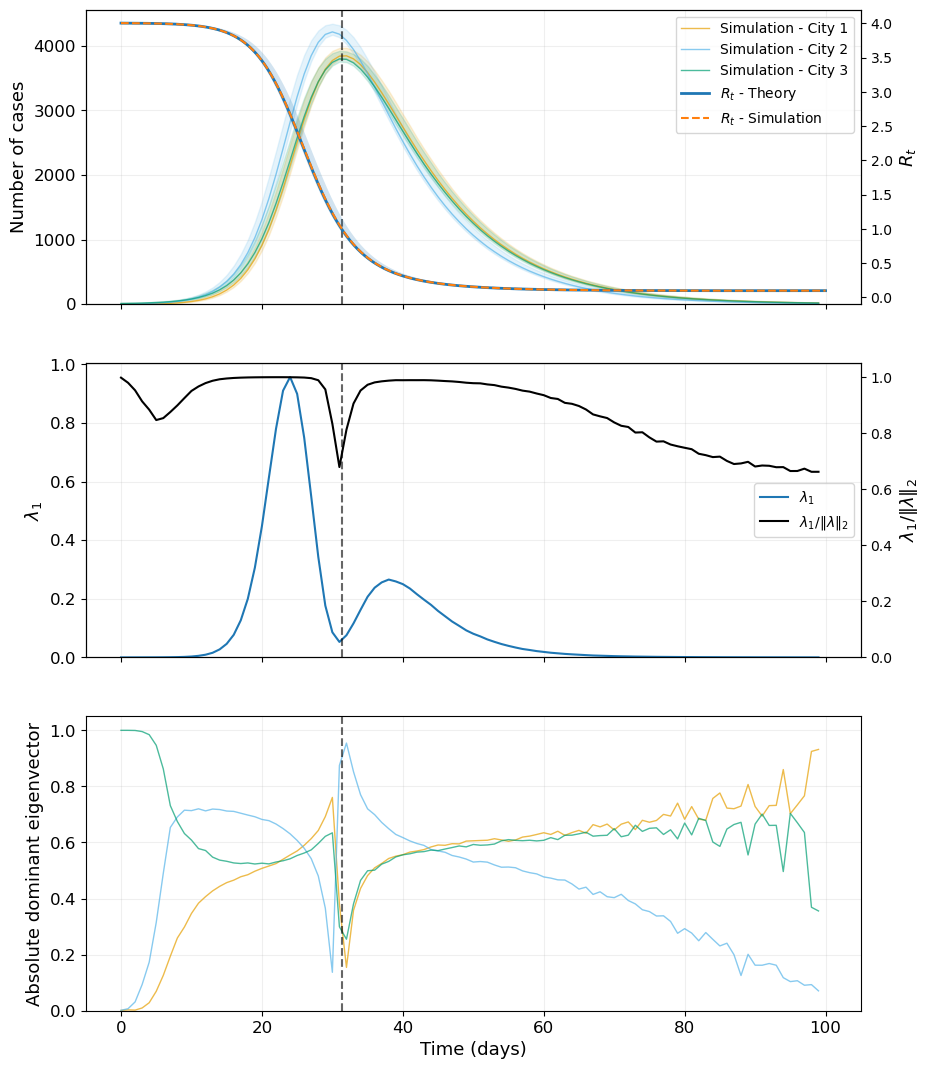

In [18]:
N_cities = 3
T_max = 100
b_w = 0.231
b_b = 0.12
beta_matrix = np.array([[b_w,b_b,0],[b_b,b_w,b_b],[0,b_b,b_w]])
gamma = 0.1
mu = 1/(80*365)
N_population = 100000

Ii = np.array([0,0,100])
Si = N_population - Ii

betat = lambda t: beta_matrix
results_between = analyze_epidemic_data('seed', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single(results_between, ts, save_path='Rev_Figures/seed_cases.pdf')

/tmp/ipykernel_6870/1529226588.py:7: RuntimeWarning: invalid value encountered in scalar divide
  norm_eigvals = [np.max(np.linalg.eigvalsh(cov[i]))/np.linalg.norm(np.linalg.eigvalsh(cov[i]))
/tmp/ipykernel_6870/1529226588.py:34: RuntimeWarning: invalid value encountered in scalar divide
  sim_norm_eigvals = [np.max(np.linalg.eigvalsh(covariances[:,:,i]))/


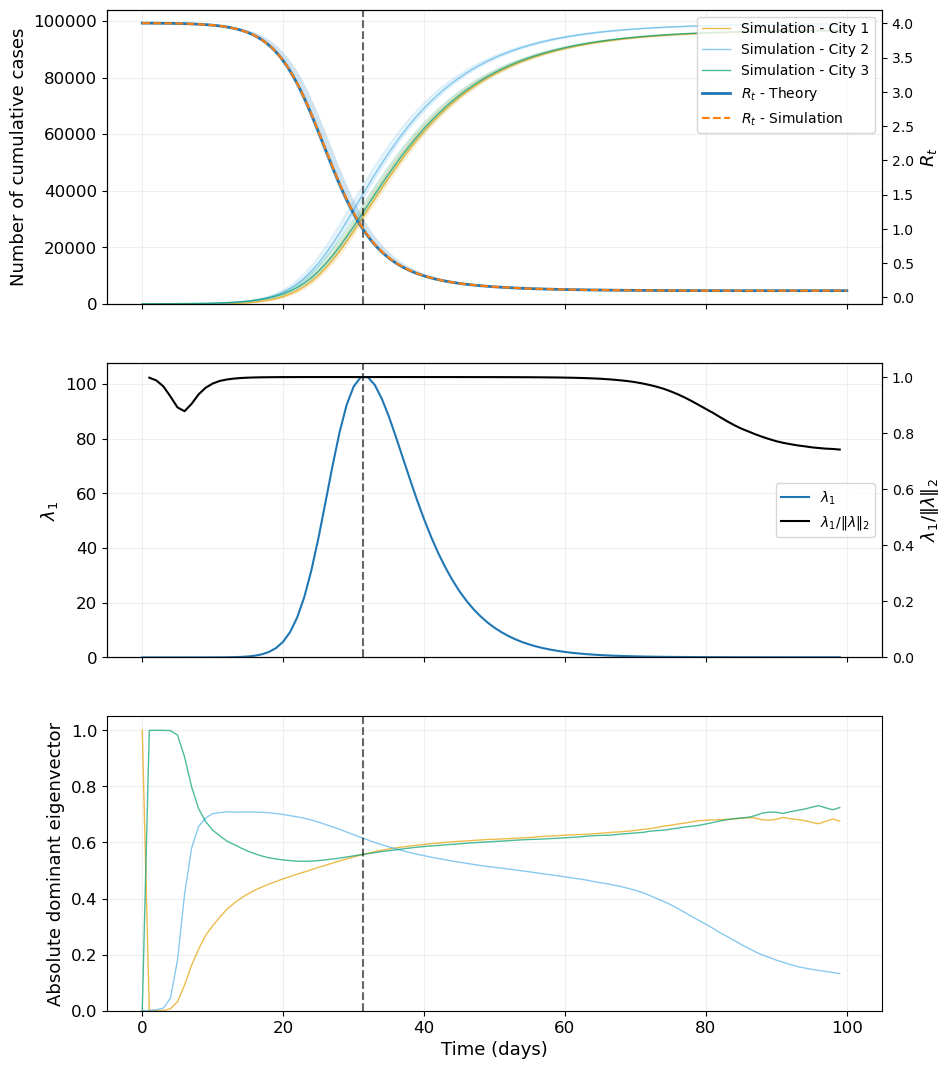

In [19]:
results_between = analyze_epidemic_data_cumulative('seed', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single_cumulative(results_between, ts, save_path='Rev_Figures/seed_cases_cumulative.pdf')